# Практическая работа № 2. Обнинск

Граница и **298 кварталов согласованы пользователем**. Повторная нарезка не выполняется.
Первый выполненный этап сохранён в `boundary_stage_executed.ipynb`; карта — `boundary_blocks_review.html`.

Ноутбук выполняется последовательно на локальных данных, без скачивания. Ядро: Python из `.venv`.
Код всех расчётов приведён в ячейках; `research_pipeline.py` — их редактируемый источник.
Здесь используются BlocksNet 1.0.0a9 и OSMnx 2.1.1, площади в EPSG:32637, экспорт в EPSG:4326.

**Уточнение населения.** Первоначальные 198 871 житель и все первоначальные результаты сохранены в
`population_initial/`. Проверка садовых зон выявила только 1 087 модельных жителей (0,55%):
их исключение не объясняет основное завышение. В итоговом сценарии постоянное население садов равно нулю;
это модельное допущение, а не утверждение об отсутствии регистрации.

Крупнейшие кварталы проверены отдельно: `population_top10_blocks_audit.csv`. Для восстановленной
этажности жилья использованы только наблюдаемые этажи сопоставимых жилых зданий: 3–5 аналогов,
площадь основания ×0,5–2, та же зона, расстояние до 500 м. Исходная этажность OSM не переписывается.
Устранена ошибка ТЦ «Самсон»: коммерческое здание было ошибочно заселено и получило 9 этажей.
Атрибуты и источники каждой корректировки доступны в `population_building_audit.csv`.

**Статистическая территория.** Уточнение показало: отношения OSM города 3396088 и городского округа
1192998 имеют геометрически одинаковые контуры. Росстат в сборнике городов 2024 приводит одинаковую
численность города и округа на 01.01.2024 (132,5 тыс.). В качестве единой учебной базы использован уже
найденный округлённый ориентир администрации **133,0 тыс. на 01.01.2025**.
Это условная калибровка: совпадение проверено по OSM, не по юридическому цифровому контуру;
расхождение с площадью 55,03 км² в другом документе и разница дат статистики и OSM остаются ограничениями.
**Пропорция площадей территории не используется.**

Сначала сохранена уточнённая некалиброванная оценка (90% поэтажной площади жилья / 30 м² на человека).
Затем 133 000 жителей распределены пропорционально уточнённой жилой площади вне садовых зон;
округление наибольшими остатками сохраняет целочисленный итог. Население кварталов остаётся модельным,
а не официальной статистикой. Совпадение общего итога с ориентиром — следствие калибровки, не её проверка.
Пять вариантов сравниваются в `population_scenarios.csv`; геометрии и матрицы сохранены побайтно.

**Школы.** Каталог сверяется по адресам с муниципальным списком: 19 муниципальных организаций,
4 частные и отдельная государственная спортивная общеобразовательная школа со специальным отбором.
Организация не равна площадке. СОШ №18 и ФТШ делят корпус на 1000 мест; второй корпус №18 — 1144 места,
хотя OSM подписывает его №19. Два корпуса «Державы» — одна организация. Вместимость не равна числу учеников.
Для мощности без опубликованного значения используется простая **модель общая площадь / 18 м² на место**:
порядок величины согласован с опубликованным корпусом около 18 тыс. м² на 1000 мест.
Это не норматив и не официальная мощность; исходные опубликованные и модельные значения разделены.
В основной модели учтены муниципальные площадки без специального отбора; частные школы,
спортивная школа и компенсирующая начальная школа–сад №35 показаны отдельно.

**Граф.** В проверенных открытых источниках и релизах IduEdu подходящий готовый граф не найден
(`source_notes.json`, сохранены списки релизов). Это ограниченный поиск, не доказательство отсутствия графа.
**Отступление от задания:** простой пешеходный граф построен OSMnx из уже скачанной выгрузки OSM.
Вес = длина ребра / 75 м/мин (4,5 км/ч). Граф включает дороги и пешеходные пути, исключает запреты `foot=no`
и закрытые проезды. Ограды без корректных тегов, расписание ворот и сезонность могут быть не учтены.
Полный граф сохранён; матрица рассчитана готовой функцией BlocksNet на главной связной компоненте.
Между кварталами используются **сетевые** пути. Прямая привязка к узлам служит диагностикой,
не заменяет маршруты и не прибавляется к минутам. Внутренняя точка крупного квартала обобщает территорию.

**Обеспеченность.** Параметры стандартного `school` BlocksNet: 120 мест/1000 жителей, 15 минут пешком,
`competitive_provision(self_supply=True, max_depth=1)`. Места внутри своего квартала доступны сразу —
это допущение исходного pipeline, особенно существенное для крупных кварталов.
Нет застройки — морфотип, MXI, L и OSR не определены, а FSI/GSI равны нулю.
Нулевой спрос — доля обеспеченности не определена. `area_accessibility` — среднее сетевое время
до кварталов с весами по площади; меньше значит доступнее, это не процент покрытия.

Источники: [задание](https://mvin8.github.io/ai-technologies-in-urbanism/content/practice/practice-02.html),
[pipeline](https://github.com/aimclub/blocksnet/blob/main/examples/pipeline.ipynb),
[OSM · ODbL](https://www.openstreetmap.org/relation/3396088),
[население](https://obninsk.ru/obninsk/economic-development/stat/),
[школы](https://www.obninsk.ru/obninsk/social-sphere/education/Obninskschools/),
[площадь округа](https://base.garant.ru/412329080/b89690251be5277812a78962f6302560/).
Ссылки мощности конкретных школ — в `school_catalog.csv`. Выгрузка OSM получена 16.11.2026;
XML API не сообщил единую дату снимка. Не смешивайте её с датой статистического населения.


## 1. Согласованная территория и локальные данные

In [1]:
from pathlib import Path
import hashlib
import json
import os
import sys

DATA = Path.cwd()
if (DATA / "examples/data/obninsk").is_dir():
    DATA = DATA / "examples/data/obninsk"
sys.path.insert(0, str(DATA))
os.environ["MPLCONFIGDIR"] = str(DATA / "cache/matplotlib")
os.environ["NUMBA_CACHE_DIR"] = str(DATA / "cache/numba")
os.environ["TMPDIR"] = str(DATA / "cache/tmp")
(DATA / "cache/tmp").mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(DATA))

import geopandas as gpd
import networkx as nx
import numpy as np
import osmnx as ox
import pandas as pd
from IPython.display import Markdown, display
from blocksnet.blocks.assignment import assign_land_use
from blocksnet.blocks.aggregation import aggregate_objects
from blocksnet.preprocessing.imputing import impute_buildings, impute_services
from blocksnet.enums import LandUse
from blocksnet.relations import calculate_accessibility_matrix
from blocksnet.analysis.provision import competitive_provision
from blocksnet.analysis.indicators import calculate_density_indicators
from blocksnet.analysis.morphotypes import get_spacematrix_morphotypes, get_strelka_morphotypes
from blocksnet.analysis.network.accessibility import area_accessibility
from blocksnet.config import service_types_config
from visuals import METRICS, indicator_map, translate
from population_revision import revise_attributes, calibrate_population

ox.settings.use_cache = False
ox.settings.log_file = False
ox.settings.cache_folder = DATA / "cache/osmnx"
ox.settings.logs_folder = DATA / "cache/logs"
CRS = 32637
blocks = gpd.read_file(DATA / "blocks_review.geojson").set_index("block_id").sort_index().to_crs(CRS)
blocks.index.name = "block_id"
assert len(blocks) == 298 and blocks.index.is_unique and blocks.geometry.is_valid.all()
boundary = gpd.read_file(DATA / "boundary.geojson").to_crs(CRS)
source_hash = hashlib.sha256((DATA / "blocks_review.geojson").read_bytes()).hexdigest()
frozen = DATA / "approved_blocks.json"
if frozen.exists():
    assert json.loads(frozen.read_text())["sha256"] == source_hash, "Согласованная геометрия изменилась"
else:
    frozen.write_text(json.dumps({"count": 298, "sha256": source_hash,
        "source": "blocks_review.geojson", "status": "Согласовано пользователем"}, ensure_ascii=False, indent=2))
response = json.loads((DATA / "cutting_osm.json").read_text())
features = gpd.read_parquet(DATA / "research_features.parquet").to_crs(CRS)
features["osm_key"] = [f"{kind}/{osm_id}" for kind, osm_id in features.index]
features = features.reset_index(drop=True)
print(f"Закреплены {len(blocks)} кварталов; граница {boundary.area.sum() / 1e6:.2f} км². Новых запросов OSM нет.")

Закреплены 298 кварталов; граница 43.84 км². Новых запросов OSM нет.


## 2. Функциональное использование

In [2]:
zones = features[features.landuse.notna() & features.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
zones = zones[["geometry", "landuse"]].rename(columns={"landuse": "functional_zone"}).reset_index(drop=True)
rules = {
    "residential": LandUse.RESIDENTIAL, "commercial": LandUse.BUSINESS, "retail": LandUse.BUSINESS,
    "industrial": LandUse.INDUSTRIAL, "garages": LandUse.INDUSTRIAL, "brownfield": LandUse.INDUSTRIAL,
    "forest": LandUse.RECREATION, "grass": LandUse.RECREATION, "flowerbed": LandUse.RECREATION,
    "recreation_ground": LandUse.RECREATION, "allotments": LandUse.AGRICULTURE,
    "farmland": LandUse.AGRICULTURE, "farmyard": LandUse.AGRICULTURE,
    "cemetery": LandUse.SPECIAL, "military": LandUse.SPECIAL, "religious": LandUse.SPECIAL,
    "construction": LandUse.SPECIAL,
}
assigned = assign_land_use(blocks[["geometry"]].copy(), zones, rules)
blocks["land_use"] = assigned.land_use.map(lambda v: v.value if isinstance(v, LandUse) else None)
blocks["land_use_share"] = assigned["share"]
zones.to_crs(4326).to_file(DATA / "functional_zones.geojson", driver="GeoJSON")
display(blocks.land_use.fillna("Нет данных OSM").value_counts().to_frame("Кварталов"))

,Кварталов
land_use,
residential,97
Нет данных OSM,80
agriculture,61
recreation,24
industrial,23
business,7
special,6


## 3. Полнота зданий до моделирования

In [3]:
buildings = features[features.building.notna() & features.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
buildings = buildings.reset_index(drop=True)
buildings["geometry"] = buildings.geometry.make_valid()
buildings = buildings[buildings.area > 1].reset_index(drop=True)
buildings["building_raw"] = buildings.building
buildings["levels_raw"] = buildings.get("building:levels")
buildings["number_of_floors"] = pd.to_numeric(buildings.levels_raw, errors="coerce")
buildings.loc[~buildings.number_of_floors.between(1, 60), "number_of_floors"] = np.nan
buildings["footprint_area"] = buildings.area
quality = pd.DataFrame({"Атрибут": ["Задано назначение (не building=yes)", "Корректная этажность", "Высота"],
    "Объектов": [int(buildings.building.ne("yes").sum()), int(buildings.number_of_floors.notna().sum()),
                  int(buildings.get("height", pd.Series(dtype=str)).notna().sum())]})
quality["Доля, %"] = (quality["Объектов"] / len(buildings) * 100).round(1)
quality.to_csv(DATA / "building_completeness.csv", index=False)
buildings.to_parquet(DATA / "buildings_raw.parquet")
display(quality)
print("Всего контуров:", len(buildings))
# Исключаем вложенные секции, если внешний контур уже описывает целое здание.
pairs = buildings.sjoin(buildings[["geometry"]].rename_axis(None), predicate="intersects")
pairs = pairs[pairs.index < pairs.index_right]
nested = set()
for bid, pair in pairs.iterrows():
    other_id = pair.index_right
    first, second = buildings.geometry.loc[bid], buildings.geometry.loc[other_id]
    if first.intersection(second).area >= 0.99 * min(first.area, second.area):
        nested.add(bid if first.area < second.area else other_id)
buildings.loc[sorted(nested)].to_parquet(DATA / "buildings_nested_excluded.parquet")
buildings = buildings.drop(index=sorted(nested)).reset_index(drop=True)
print("Вложенных секций исключено из повторного учёта:", len(nested))

,Атрибут,Объектов,"Доля, %"
0,Задано назначение (не building=yes),1849,33.2
1,Корректная этажность,1980,35.5
2,Высота,62,1.1


Всего контуров: 5572


Вложенных секций исключено из повторного учёта: 110


## 4. Восстановление назначения и этажности; население

In [4]:
# Зона здания определяется максимальным пересечением, без перевода всех неизвестных зданий в нежилые.
building_zones = gpd.overlay(buildings[["geometry"]].reset_index().rename(columns={"index": "bid"}),
                             zones.rename(columns={"functional_zone": "zone"}), how="intersection")
building_zones["intersection_area"] = building_zones.area
dominant = building_zones.sort_values("intersection_area").drop_duplicates("bid", keep="last").set_index("bid")
buildings["zone"] = buildings.index.to_series().map(dominant.zone)
living_types = ["apartments", "residential", "house", "detached", "semidetached_house", "terrace", "dormitory"]
buildings["is_living"] = buildings.building.isin(living_types)
buildings["use_source"] = np.where(buildings.building.eq("yes"), "неизвестно", "тип OSM")
unknown = buildings.building.eq("yes")
institution = buildings.get("amenity", pd.Series(index=buildings.index, dtype=str)).notna()
school_sites = features[features.amenity.eq("school") & features.geom_type.isin(["Polygon", "MultiPolygon"])]
institution |= buildings.representative_point().within(school_sites.geometry.union_all())
school_keys = pd.read_csv(DATA / "school_catalog.csv").osm_key
institution |= buildings.osm_key.isin(school_keys)
for tag in ["shop", "office", "craft", "tourism", "leisure", "power", "industrial"]:
    if tag in buildings:
        institution |= buildings[tag].notna()
nonres_zone = buildings.zone.isin(["industrial", "garages", "commercial", "retail", "military", "cemetery"])
small_outbuilding = buildings.footprint_area < 45
residential_zone = buildings.zone.eq("residential")
allotment_house = buildings.zone.eq("allotments") & buildings.footprint_area.between(45, 300)
candidate = unknown & ~institution & ~nonres_zone & ~small_outbuilding
buildings.loc[candidate & (residential_zone | allotment_house), "is_living"] = True
buildings.loc[unknown & institution, "use_source"] = "общественный объект OSM/каталога школ"
buildings.loc[unknown & ~institution & nonres_zone, "use_source"] = "нежилая зона OSM"
buildings.loc[unknown & ~institution & ~nonres_zone & small_outbuilding, "use_source"] = "малый вспомогательный контур <45 м²"
buildings.loc[candidate & (residential_zone | allotment_house), "use_source"] = "жилая зона/садовый дом"
buildings.loc[institution, "is_living"] = False
# Для оставшихся — ближайшие 5 зданий с известным типом в пределах 250 м и той же размерной группы.
size_group = pd.cut(buildings.footprint_area, [0, 150, 500, 2000, np.inf], labels=False)
unresolved = buildings.index[buildings.use_source.eq("неизвестно")]
known = buildings[~unknown & ~small_outbuilding]
for bid in unresolved:
    analogs = known[size_group.loc[known.index].eq(size_group.loc[bid])]
    distances = analogs.geometry.distance(buildings.at[bid, "geometry"].representative_point())
    nearest = distances[distances <= 250].nsmallest(5).index
    residential = len(nearest) >= 2 and analogs.loc[nearest, "is_living"].mean() >= 0.6
    buildings.at[bid, "is_living"] = residential
    buildings.at[bid, "use_source"] = "аналоги 250 м" if len(nearest) >= 2 else "неопределённое, консервативно нежилое"

buildings["floors_source"] = np.where(buildings.number_of_floors.notna(), "этажность OSM", "")
height = pd.to_numeric(buildings.get("height", pd.Series(index=buildings.index, dtype=str))
                       .astype(str).str.replace(" m", "", regex=False), errors="coerce")
from_height = buildings.number_of_floors.isna() & height.between(3, 180)
buildings.loc[from_height, "number_of_floors"] = (height[from_height] / 3).round().clip(1, 60)
buildings.loc[from_height, "floors_source"] = "высота OSM / 3 м"
observed = buildings[buildings.number_of_floors.notna()].copy()
for bid in buildings.index[buildings.number_of_floors.isna()]:
    row = buildings.loc[bid]
    same_type = observed.building.eq(row.building) if row.building != "yes" else observed.is_living.eq(row.is_living)
    analogs = observed[same_type & size_group.loc[observed.index].eq(size_group.loc[bid])]
    if pd.notna(row.zone):
        analogs = analogs[analogs.zone.eq(row.zone)]
    distance = analogs.geometry.distance(row.geometry.representative_point())
    nearest = distance[distance <= 500].nsmallest(5).index
    if len(nearest) >= 2:
        floors = analogs.loc[nearest, "number_of_floors"].median()
        origin = "медиана аналогов до 500 м"
    elif len(analogs) >= 3:
        floors = analogs.number_of_floors.median()
        origin = "медиана типа/размера/зоны"
    else:
        floors = 2 if row.is_living and row.footprint_area < 300 else 5 if row.is_living else 3 if row.building == "school" else 1
        origin = "типовая оценка типа и площади"
    buildings.at[bid, "number_of_floors"] = max(1, round(floors))
    buildings.at[bid, "floors_source"] = origin

buildings = revise_attributes(buildings, DATA)
building_attributes = buildings.drop(columns="geometry").copy()
buildings = impute_buildings(buildings, default_living_demand=30, living_area_coefficient=0.9)
# Схемы BlocksNet удаляют дополнительные столбцы; возвращаем происхождение модельных атрибутов.
for column in building_attributes.columns.difference(buildings.columns):
    buildings[column] = building_attributes[column]
buildings["population"] = buildings.population.fillna(0)
buildings = calibrate_population(buildings, DATA)
buildings["population_osm"] = np.nan  # Исходной статистики населения зданий в OSM нет.
buildings.to_parquet(DATA / "buildings_model.parquet")
export_columns = ["osm_key", "building_raw", "levels_raw", "is_living", "use_source", "number_of_floors",
                  "floors_source", "footprint_area", "build_floor_area", "living_area", "non_living_area",
                  "population_osm", "population_initial", "population_before_seasonality", "population_uncalibrated",
                  "population_model", "population_source", "seasonal_garden", "revision_note", "geometry"]
buildings[export_columns].to_crs(4326).to_file(DATA / "buildings_model.geojson", driver="GeoJSON")
building_agg, excess_buildings = aggregate_objects(blocks[["geometry"]], buildings[
    ["geometry", "footprint_area", "build_floor_area", "living_area", "non_living_area", "population"]])
assert excess_buildings.empty, f"Не привязано зданий: {len(excess_buildings)}"
for column in ["footprint_area", "build_floor_area", "living_area", "non_living_area", "population", "count"]:
    blocks[column if column != "count" else "buildings_count"] = building_agg[column]
blocks["population"] = blocks.population.astype(int)
blocks["site_area"] = blocks.area
blocks["population_density"] = blocks.population / blocks.site_area * 10000
population_comparison = pd.DataFrame([
    {"Источник": "Первоначальная модель (сохранена)", "Год/дата": "OSM 2026", "Население": 198871},
    {"Источник": "Уточнённая некалиброванная модель без постоянного населения садов", "Год/дата": "OSM 2026", "Население": int(buildings.population_uncalibrated.sum())},
    {"Источник": "Калиброванная модель территории 43,84 км²", "Год/дата": "ориентир 01.01.2025; веса OSM 2026", "Население": int(blocks.population.sum())},
    {"Источник": "Администрация: городской округ (округлено)", "Год/дата": "01.01.2025", "Население": 133000},
])
population_comparison.to_csv(DATA / "population_comparison.csv", index=False)
display(buildings.use_source.value_counts().to_frame("Зданий"))
display(buildings.floors_source.value_counts().to_frame("Зданий"))
display(population_comparison)
display(pd.read_csv(DATA / "population_scenarios.csv"))
print("Отличие от официального ориентира, %:", round((blocks.population.sum() / 133000 - 1) * 100, 1))

.venv/lib/python3.12/site-packages/geopandas/tools/overlay.py:386: UserWarning: `keep_geom_type=True` in overlay resulted in 68 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  result = _collection_extract(result, geom_type, keep_geom_type_warning)


2026-11-16 19:56:10.073 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column build_floor_area not found and will be initialized as None


2026-11-16 19:56:10.074 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column living_area not found and will be initialized as None


2026-11-16 19:56:10.074 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column non_living_area not found and will be initialized as None


2026-11-16 19:56:10.075 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column population not found and will be initialized as None


.venv/lib/python3.12/site-packages/geopandas/geodataframe.py:2011: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  super().__setitem__(key, value)
.venv/lib/python3.12/site-packages/geopandas/geodataframe.py:2011: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  super().__setitem__(key, value)
.venv/lib/python3.12/site-packages/geopandas/geodataframe.py:2011: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns a

... (3 outputs left out)

,Зданий
floors_source,
этажность OSM,1979
"проверка: 3–5 жилых аналогов ×0,5–2 площади до 500 м",1532
медиана типа/размера/зоны,917
медиана аналогов до 500 м,748
типовая оценка типа и площади,271
высота OSM / 3 м,14
"ТЦ Самсон: 1 этаж по карточке объекта, не официальный реестр",1


,Источник,Год/дата,Население
0,Первоначальная модель (сохранена),OSM 2026,198871
1,Уточнённая некалиброванная модель без постоянн...,OSM 2026,196763
2,"Калиброванная модель территории 43,84 км²",ориентир 01.01.2025; веса OSM 2026,133000
3,Администрация: городской округ (округлено),01.01.2025,133000


,Вариант,Население,"Отклонение от ориентира, %"
0,Первоначальная модель,198871,49.527068
1,Только исключение садов из первоначальной модели,197784,48.709774
2,"Уточнённые атрибуты, сады заселены как прежде",197850,48.759398
3,"Уточнённые атрибуты, постоянное население без ...",196763,47.942105
4,Калиброванное распределение ориентира 01.01.2025,133000,0.000000


Отличие от официального ориентира, %: 0.0


## 5. Школы: проверенные площадки и вместимость

In [5]:
catalog = pd.read_csv(DATA / "school_catalog.csv")
campuses = []
for record in catalog.to_dict("records"):
    if record["geometry_source"] == "campus":
        site = features.loc[features.osm_key.eq(record["osm_key"]), "geometry"].iloc[0]
        school_buildings = buildings[buildings.geometry.representative_point().within(site)]
        school_buildings = school_buildings[school_buildings.building.eq("school")]
        if school_buildings.empty:
            # Для новых школ OSM может содержать building=yes; основной корпус — крупнейший контур на участке.
            inside = buildings[buildings.geometry.representative_point().within(site)]
            school_buildings = inside.nlargest(1, "footprint_area")
    else:
        school_buildings = buildings[buildings.osm_key.eq(record["osm_key"])]
        site = school_buildings.geometry.union_all()
    assert not site.is_empty, record["name"]
    floor_area = school_buildings.build_floor_area.sum()
    record["floor_area_model"] = float(floor_area)
    record["geometry"] = site.representative_point()
    record["capacity_raw"] = record["capacity_official"]
    if pd.notna(record["capacity_official"]):
        record["capacity"] = int(record["capacity_official"])
        record["capacity_source"] = "опубликованная проектная мощность"
    elif floor_area > 0:
        record["capacity"] = max(20, int(round(floor_area / 18 / 10) * 10))
        record["capacity_source"] = "модель: общая площадь / 18 м² на место"
    else:
        record["capacity"] = np.nan
        record["capacity_source"] = "типовой минимум BlocksNet"
    campuses.append(record)
schools = gpd.GeoDataFrame(campuses, crs=CRS)
school_attributes = schools.drop(columns="geometry").copy()
schools = impute_services(schools, "school")
for column in school_attributes.columns.difference(schools.columns):
    schools[column] = school_attributes[column]
schools["capacity"] = schools.capacity.astype(float)
# В общем здании ЧаШи/№9 и начальной школе–саду доля школьных помещений неизвестна.
unknown_share = schools["name"].str.contains("ЧаШа|№35", regex=True)
schools.loc[unknown_share, "capacity"] = np.nan
schools.loc[unknown_share, "capacity_source"] = "не определена: неизвестна доля школьных помещений"
schools["capacity_baseline"] = schools.capacity.where(schools.public_supply.eq(1), 0)
school_agg, excess_schools = aggregate_objects(blocks[["geometry"]], schools[
    ["geometry", "capacity_baseline"]].rename(columns={"capacity_baseline": "capacity"}))
assert excess_schools.empty
blocks["capacity"] = school_agg.capacity.astype(int)
blocks["schools_count"] = school_agg["count"].astype(int)
schools["block_id"] = gpd.sjoin(schools[["geometry"]], blocks[["geometry"]].rename_axis(None), predicate="within")["index_right"]
assert schools.block_id.notna().all()
schools.to_crs(4326).to_file(DATA / "schools.geojson", driver="GeoJSON")
schools.drop(columns="geometry").to_csv(DATA / "schools.csv", index=False)
display(schools[["name", "capacity", "capacity_source", "public_supply", "block_id"]])
print("Площадок в каталоге:", len(schools), "; мест в основной модели:", blocks.capacity.sum())

2026-11-16 19:56:11.098 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input


2026-11-16 19:56:11.099 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


,name,capacity,capacity_source,public_supply,block_id
0,СОШ № 1,300.0,модель: общая площадь / 18 м² на место,1,10
1,СОШ № 3,330.0,модель: общая площадь / 18 м² на место,1,116
2,СОШ № 4,380.0,модель: общая площадь / 18 м² на место,1,60
3,СОШ № 5,270.0,модель: общая площадь / 18 м² на место,1,20
4,СОШ № 6,390.0,модель: общая площадь / 18 м² на место,1,30
5,СОШ № 7,450.0,модель: общая площадь / 18 м² на место,1,30
6,СОШ № 9,370.0,модель: общая площадь / 18 м² на место,1,73
7,СОШ № 10,560.0,модель: общая площадь / 18 м² на место,1,73
8,СОШ № 11,580.0,модель: общая площадь / 18 м² на место,1,31
9,СОШ № 12,390.0,модель: общая площадь / 18 м² на место,1,113


Площадок в каталоге: 25 ; мест в основной модели: 9664


## 6. Пешеходный граф OSMnx, 4,5 км/ч

,0,1,2,3,4
block_id,,,,,
0,0.00,18.67,48.73,54.51,83.41
1,18.67,0.00,34.96,40.65,87.03
2,48.73,34.96,0.00,10.02,61.77
3,54.51,40.65,10.02,0.00,65.84
4,83.41,87.03,61.77,65.84,0.00


Распределение минут между разными кварталами:


count    88506.00
mean        58.40
std         30.16
min          0.00
25%         34.77
50%         57.78
75%         80.33
max        158.04
dtype: float64

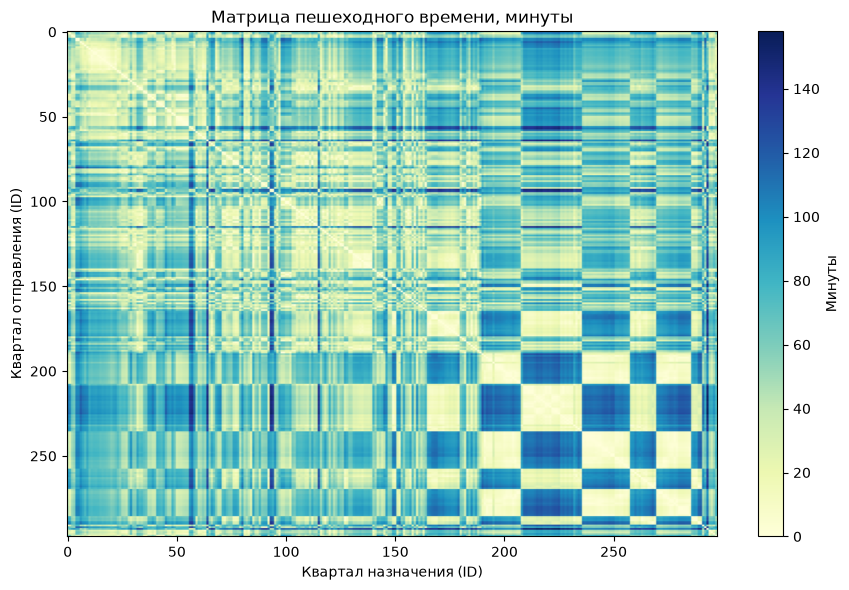

,Значение
nodes_full,10856
edges_full,31562
components,39
main_nodes,10748
main_share,0.990052
blocks_snap_over_250m,2
schools_snap_max_m,116.72148
all_blocks_mutually_reachable,True
walking_speed_kmh,4.5
residential_points,2986


In [6]:
graph_path = DATA / "walk_graph.graphml"
if graph_path.exists():
    graph_full = ox.load_graphml(graph_path, edge_dtypes={"time_min": float, "length_meter": float})
else:
    forbidden = {"motorway", "motorway_link", "construction", "proposed", "raceway", "bus_guideway", "platform"}
    ways = []
    for element in response["elements"]:
        tags = element.get("tags", {})
        if element["type"] != "way" or not tags.get("highway") or tags["highway"] in forbidden:
            continue
        if tags.get("area") == "yes" or tags.get("foot") in {"no", "private"}:
            continue
        if tags.get("access") in {"no", "private"} and tags.get("foot") not in {"yes", "designated", "permissive"}:
            continue
        ways.append(element)
    node_ids = {node for way in ways for node in way["nodes"]}
    nodes = [e for e in response["elements"] if e["type"] == "node" and e["id"] in node_ids]
    graph_full = ox.graph._create_graph([{"elements": nodes + ways}], bidirectional=True)
    graph_full = ox.simplify_graph(graph_full)
    graph_full = ox.project_graph(graph_full, to_crs=CRS)
    for _, _, edge in graph_full.edges(data=True):
        edge["time_min"] = edge["length"] / 75
        edge["length_meter"] = edge["length"]
    graph_full.graph["crs"] = CRS
    graph_full.graph["walk_speed_kmh"] = 4.5
    ox.save_graphml(graph_full, graph_path)

components = sorted(nx.weakly_connected_components(graph_full), key=len, reverse=True)
# iduedu оставляет главную компоненту; делаем это явно и сохраняем полный граф и диагностику.
main = graph_full.subgraph(components[0]).copy()
# iduedu использует номера узлов как позиции CSR и требует компактные int32, а OSM ID могут быть >2³¹.
main = nx.convert_node_labels_to_integers(main, label_attribute="osmid_original")
graph = nx.DiGraph()
graph.graph.update(main.graph)
graph.graph["crs"] = CRS
graph.add_nodes_from(main.nodes(data=True))
# Минимум из параллельных рёбер: iduedu иначе выбирает произвольное последнее ребро.
for u, v, edge in main.edges(data=True):
    if not graph.has_edge(u, v) or edge["time_min"] < graph[u][v]["time_min"]:
        graph.add_edge(u, v, **edge)
assert nx.is_strongly_connected(graph)
block_points = blocks.copy()
block_points["geometry"] = blocks.geometry.representative_point()
block_nodes, snap = ox.distance.nearest_nodes(main, block_points.geometry.x, block_points.geometry.y, return_dist=True)
blocks["network_snap_m"] = snap
for i, node in zip(block_points.index, block_nodes):
    block_points.at[i, "geometry"] = __import__("shapely").Point(graph.nodes[node]["x"], graph.nodes[node]["y"])
school_nodes, school_snap = ox.distance.nearest_nodes(main, schools.geometry.x, schools.geometry.y, return_dist=True)
schools["network_snap_m"] = school_snap
# Матрица — строго по рёбрам, без евклидовых добавок и скрытой скорости 5 км/ч из iduedu.
matrix_path = DATA / "travel_time_minutes.csv"
if matrix_path.exists():
    matrix = pd.read_csv(matrix_path, index_col=0)
    matrix.columns = matrix.columns.astype(int)
    matrix.index = matrix.index.astype(int)
else:
    matrix = calculate_accessibility_matrix(block_points[["geometry"]], graph, weight_key="time_min",
        dtype=np.float64, add_dist_tofrom_node=False, max_workers=2)
    matrix.index.name = "block_id"
    matrix.to_csv(matrix_path)
assert matrix.index.equals(blocks.index) and matrix.columns.equals(blocks.index)
assert np.isfinite(matrix.to_numpy()).all() and np.allclose(np.diag(matrix), 0)
assert np.allclose(matrix.to_numpy(), matrix.to_numpy().T)
for origin, destination in [(0, 149), (32, 70), (100, 260)]:
    expected = nx.shortest_path_length(graph, int(block_nodes[origin]), int(block_nodes[destination]),
        weight=lambda u, v, edge: float(np.round(edge["time_min"] * 100)) / 100)
    assert abs(matrix.loc[origin, destination] - expected) < 0.011
display(matrix.iloc[:5, :5].round(2))
print("Распределение минут между разными кварталами:")
display(pd.Series(matrix.to_numpy()[~np.eye(298, dtype=bool)]).describe().round(2))
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 6))
image = ax.imshow(matrix, cmap="YlGnBu", aspect="auto")
ax.set(xlabel="Квартал назначения (ID)", ylabel="Квартал отправления (ID)", title="Матрица пешеходного времени, минуты")
fig.colorbar(image, ax=ax, label="Минуты")
fig.tight_layout()
fig.savefig(DATA / "travel_time_matrix.png", dpi=150)
display(fig)
plt.close(fig)
# Фактические точки школ: отдельная сетевая проверка; основная обеспеченность — как в pipeline, по кварталам.
from iduedu import get_adj_matrix_gdf_to_gdf
school_points = schools[["geometry"]].copy()
school_points["geometry"] = [__import__("shapely").Point(graph.nodes[n]["x"], graph.nodes[n]["y"]) for n in school_nodes]
# Согласованную транспортную матрицу до школьных узлов читаем без перезаписи.
school_matrix = pd.read_csv(DATA / "school_travel_time_minutes.csv", index_col=0)
school_matrix.index = school_matrix.index.astype(int)
school_matrix.columns = school_matrix.columns.astype(int)
blocks["nearest_school_minutes"] = school_matrix.loc[:, schools.public_supply.eq(1)].min(axis=1)
residential_points = buildings[buildings.population.gt(0)].copy()
residential_points["geometry"] = residential_points.geometry.representative_point()
original_nearest = ox.distance.nearest_nodes(graph_full, residential_points.geometry.x, residential_points.geometry.y)
_, residential_snap = ox.distance.nearest_nodes(main, residential_points.geometry.x,
                                               residential_points.geometry.y, return_dist=True)
residential_points["nearest_component_is_main"] = [node in components[0] for node in original_nearest]
residential_points["main_network_snap_m"] = residential_snap
residential_points[["osm_key", "population", "nearest_component_is_main", "main_network_snap_m"]].to_csv(
    DATA / "residential_network_check.csv", index=False)
original_school_nearest = ox.distance.nearest_nodes(graph_full, schools.geometry.x, schools.geometry.y)
schools["nearest_component_is_main"] = [node in components[0] for node in original_school_nearest]
network_quality = {"nodes_full": graph_full.number_of_nodes(), "edges_full": graph_full.number_of_edges(),
    "components": len(components), "component_sizes": [len(c) for c in components],
    "main_nodes": len(main), "main_share": len(main) / len(graph_full),
    "blocks_snap_over_250m": int((snap > 250).sum()), "schools_snap_max_m": float(max(school_snap)),
    "all_blocks_mutually_reachable": True, "walking_speed_kmh": 4.5,
    "residential_points": len(residential_points),
    "residential_nearest_in_other_components": int((~residential_points.nearest_component_is_main).sum()),
    "residential_snap_over_250m": int((residential_snap > 250).sum()),
    "schools_nearest_in_other_components": int((~schools.nearest_component_is_main).sum()),
    "model": "Сетевые минуты между ближайшими узлами главной пешеходной компоненты; без добавок по прямой"}
(DATA / "network_quality.json").write_text(json.dumps(network_quality, ensure_ascii=False, indent=2))
schools.to_crs(4326).to_file(DATA / "schools.geojson", driver="GeoJSON")
display(pd.Series({k: v for k, v in network_quality.items() if k != "component_sizes"}).to_frame("Значение"))

## 7. Конкурентная обеспеченность школами

In [7]:
school_config = service_types_config["school"]
demand_rate = int(school_config["demand"])
threshold = int(school_config["accessibility"])
provision, links = competitive_provision(blocks[["population", "capacity"]].copy(), matrix,
    accessibility=threshold, demand=demand_rate, self_supply=True, max_depth=1)
for column in provision.columns:
    if column not in blocks:
        blocks[column] = provision[column]
blocks["unmet_demand"] = blocks.demand_left.astype(int)
links.to_csv(DATA / "school_allocation_links.csv")
provision.to_csv(DATA / "baseline_provision.csv", index_label="block_id")
parameters = {"service": "school", "demand_per_1000": demand_rate, "accessibility_minutes": threshold,
    "walking_speed_kmh": 4.5, "self_supply": True, "max_depth": 1,
    "population_method": "Условное распределение 133000 жителей на 01.01.2025 по уточнённой жилой площади вне садовых зон; целочисленное округление наибольшими остатками",
    "population_calibration": True, "population_scope_check": "population_scope_check.json",
    "permanent_garden_occupancy": 0, "official_population": 133000, "official_population_date": "2025-01-01",
    "official_population_rounded": True, "official_population_source": "https://obninsk.ru/obninsk/economic-development/stat/",
    "supply_scope": "Муниципальные школьные площадки; частные, спортивная школа с отбором и компенсирующая школа–сад №35 исключены",
    "unknown_capacity_method": "модельная общая площадь учебных корпусов / 18 м² на место",
    "graph_source": "OSMnx на сохранённой XML-выгрузке OSM; подходящий готовый граф не найден",
    "blocks_sha256": source_hash, "future_scenarios_places": [600, 300, 300],
    "future_scenarios": {"one_school": [600], "two_schools": [300, 300]}}
(DATA / "school_parameters.json").write_text(json.dumps(parameters, ensure_ascii=False, indent=2))
print(f"Спрос: {blocks.demand.sum():,.0f}; мест: {blocks.capacity.sum():,.0f}; "
      f"обслужено за {threshold} мин: {blocks.demand_within.sum():,.0f}; "
      f"неудовлетворённый спрос: {blocks.unmet_demand.sum():,.0f}")
print("Конкурентная обеспеченность города:", round(blocks.demand_within.sum() / blocks.demand.sum() * 100, 1), "%")

2026-11-16 19:56:19.210 | INFO     | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:29 - Initializing provision DataFrame


2026-11-16 19:56:19.211 | WARNING  | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:33 - No demand in columns. Imputing using population column and demand parameter


2026-11-16 19:56:19.223 | INFO     | blocksnet.analysis.provision.competitive.core:_supply_self:56 - Supplying blocks with own capacities


2026-11-16 19:56:19.228 | INFO     | blocksnet.analysis.provision.competitive.core:competitive_provision:190 - Setting and solving LP problems until max depth or break condition reached


2026-11-16 19:56:19.380 | SUCCESS  | blocksnet.analysis.provision.competitive.core:competitive_provision:203 - Provision assessment finished


Спрос: 16,015; мест: 9,664; обслужено за 15 мин: 9,203; неудовлетворённый спрос: 6,812
Конкурентная обеспеченность города: 57.5 %


## 8. FSI, GSI, MXI, L, OSR и морфотипы

In [8]:
density = calculate_density_indicators(blocks[["site_area", "footprint_area", "build_floor_area",
    "living_area", "non_living_area"]].copy())
for column in ["fsi", "gsi", "mxi", "l", "osr"]:
    blocks[column] = density[column].replace([np.inf, -np.inf], np.nan)
# Без застройки FSI/GSI равны нулю, MXI/L/OSR математически не определены.
blocks.loc[blocks.build_floor_area.eq(0), ["mxi", "l", "osr"]] = np.nan
developed = blocks[blocks.build_floor_area.gt(0)][["l", "fsi", "mxi"]].copy()
spacematrix, clusters = get_spacematrix_morphotypes(developed, n_clusters=11, random_state=42)
strelka = get_strelka_morphotypes(developed)
blocks["spacematrix"] = spacematrix.morphotype
blocks["strelka"] = strelka.morphotype
clusters.to_csv(DATA / "spacematrix_clusters.csv")
blocks["area_accessibility"] = area_accessibility(matrix, blocks[["site_area"]]).area_accessibility
display(blocks[["fsi", "gsi", "mxi", "l", "osr", "area_accessibility"]].describe().round(3))

,fsi,gsi,mxi,l,osr,area_accessibility
count,298.000,298.000,178.000,178.000,178.000,298.000
mean,0.183,0.062,0.596,2.987,57.542,63.456
std,0.260,0.076,0.364,2.610,259.741,10.993
min,0.000,0.000,0.000,1.000,0.594,45.255
25%,0.000,0.000,0.224,1.809,1.925,52.973
50%,0.023,0.011,0.794,2.000,3.590,62.748
75%,0.273,0.130,0.900,3.060,8.487,72.824
max,1.456,0.398,0.900,20.022,3018.993,94.196


## 9. Сохранение результатов и проверки для практики № 3

In [9]:
for filename, digest in json.loads((DATA / "population_revision_locked_files.json").read_text()).items():
    assert hashlib.sha256((DATA / filename).read_bytes()).hexdigest() == digest, filename
assert blocks.population.sum() == 133000
assert blocks.capacity.sum() == 9664
assert buildings.loc[buildings.seasonal_garden, "population"].sum() == 0
assert (buildings["population"] >= 0).all()
assert len(blocks) == 298 and matrix.shape == (298, 298)
original = gpd.read_file(DATA / "blocks_review.geojson").set_index("block_id").sort_index()
assert np.allclose(original.to_crs(CRS).area.to_numpy(), blocks.area.to_numpy())
assert (blocks.population >= 0).all() and (blocks.capacity >= 0).all()
assert blocks.population.sum() == buildings.population.sum()
assert blocks.capacity.sum() == schools.capacity_baseline.sum()
assert (blocks.demand_within + blocks.demand_left == blocks.demand).all()
assert blocks.demand_within.sum() <= blocks.capacity.sum()
assert blocks.provision_strong.dropna().between(0, 1).all()
blocks.to_crs(4326).to_file(DATA / "blocks_results.geojson", driver="GeoJSON", index=True)
blocks.drop(columns="geometry").to_csv(DATA / "blocks_results.csv", index_label="block_id")
schools.drop(columns="geometry").to_csv(DATA / "schools.csv", index=False)
statistics = []
for key, meta in METRICS.items():
    series = blocks[key]
    if pd.api.types.is_numeric_dtype(series):
        statistics.append({"indicator": key, "title": meta["title"], "missing": int(series.isna().sum()),
            "zero": int(series.eq(0).sum()), **series.describe().to_dict()})
    else:
        series.map(translate).value_counts().to_csv(DATA / f"statistics_{key}.csv")
pd.DataFrame(statistics).to_csv(DATA / "indicator_statistics.csv", index=False)
summary = {"blocks": 298, "population_model": int(blocks.population.sum()), "school_sites": len(schools),
    "public_school_sites": int(schools.public_supply.sum()), "capacity_baseline": int(blocks.capacity.sum()),
    "demand": int(blocks.demand.sum()), "served": int(blocks.demand_within.sum()),
    "unmet_demand": int(blocks.unmet_demand.sum()),
    "provision_percent": round(float(blocks.demand_within.sum() / blocks.demand.sum() * 100), 2),
    "population_gap_percent": round(float((blocks.population.sum() / 133000 - 1) * 100), 2),
    "population_initial": 198871,
    "floors_revised_count": int(buildings.revision_note.str.startswith("этажи по").sum()),
    "population_uncalibrated": int(buildings.population_uncalibrated.sum()),
    "garden_population_initial": int(buildings.loc[buildings.seasonal_garden, "population_initial"].sum()),
    "population_calibration": True, "building_count": len(buildings), "known_levels_percent": float(quality.iloc[1]["Доля, %"]),
    "known_use_percent": float(quality.iloc[0]["Доля, %"]),
    "official_capacity_sites": int(schools.capacity_official.notna().sum()),
    "matrix_shape": list(matrix.shape), "all_checks_passed": True}
(DATA / "summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2))
practice3 = DATA / "practice3"
practice3.mkdir(exist_ok=True)
old_blocks = pd.read_csv(DATA / "population_initial/blocks_results.csv").set_index("block_id")
comparison = old_blocks[["population", "population_density", "provision_strong", "unmet_demand"]].add_suffix("_initial")
comparison = comparison.join(blocks[["population", "population_density", "provision_strong", "unmet_demand"]])
comparison.to_csv(DATA / "population_block_comparison.csv")
import shutil
for filename in ["blocks_results.geojson", "blocks_results.csv", "travel_time_minutes.csv",
                 "school_parameters.json", "baseline_provision.csv", "schools.csv", "schools.geojson",
                 "school_allocation_links.csv", "approved_blocks.json", "population_scope_check.json", "population_scenarios.csv", "population_block_comparison.csv"]:
    shutil.copy2(DATA / filename, practice3 / filename)
display(pd.Series(summary).to_frame("Результат"))

,Результат
blocks,298
population_model,133000
school_sites,25
public_school_sites,19
capacity_baseline,9664
demand,16015
served,9203
unmet_demand,6812
provision_percent,57.46
population_gap_percent,0.0


## 10. Карты, статистика и пояснение каждого показателя

In [10]:
for indicator, meta in METRICS.items():
    display(Markdown(f"### {meta['title']}\n\n{meta['description']}"))
    display(indicator_map(blocks, indicator, schools))
    values = blocks[indicator]
    if pd.api.types.is_numeric_dtype(values):
        display(values.describe().round(3).to_frame(meta["title"]))
        print(f"Нулевых значений: {values.eq(0).sum()}; отсутствующих: {values.isna().sum()}")
    else:
        display(values.map(translate).value_counts().to_frame("Кварталов"))

### Функциональное использование

Преобладающая зона OSM по площади пересечения. Это фактические теги OSM, а не Генплан.

,Кварталов
land_use,
Жилая,97
Нет данных / без застройки,80
Сельскохозяйственная / садоводство,61
Рекреационная,24
Промышленная,23
Общественно-деловая,7
Специального назначения,6


### Количество зданий

Контуры зданий, отнесённые к кварталу по внутренней точке; вспомогательные строения включены.

,Количество зданий
count,298.000
mean,18.329
std,43.439
min,0.000
25%,0.000
50%,1.500
75%,20.000
max,443.000


Нулевых значений: 120; отсутствующих: 0


### Площадь оснований зданий, м²

Сумма площадей контуров. Показывает занятую зданиями поверхность.

... (50 outputs left out)

Нулевых значений: 0; отсутствующих: 0


### Привязка квартала к сети, м

Расстояние от внутренней точки квартала до ближайшего узла основной сети. Диагностика точности, в матрицу минут не прибавляется.

,"Привязка квартала к сети, м"
count,298.000
mean,61.233
std,46.378
min,0.195
25%,29.282
50%,49.345
75%,83.575
max,292.517


Нулевых значений: 0; отсутствующих: 0


## 11. Интерактивный HTML-дашборд из сохранённых результатов

In [11]:
from generate_dashboard import generate_dashboard

generate_dashboard(DATA)
print("Создан dashboard.html. Все результаты и пакет practice3 сохранены рядом с ноутбуком.")

examples/data/obninsk/dashboard.html
Создан dashboard.html. Все результаты и пакет practice3 сохранены рядом с ноутбуком.


## Повторное использование

`blocks_results.geojson` / CSV — все показатели; `schools.geojson` / CSV — каталог и источники мощности;
`travel_time_minutes.csv` — минуты, строки и столбцы совпадают с `block_id` 0…297.
`practice3/` содержит согласованные кварталы с населением и мощностью, матрицу, параметры,
исходную обеспеченность и неудовлетворённый спрос. Сценарии 600 или 300+300 мест здесь ещё не рассчитываются.
`dashboard.html` создаётся отдельным `generate_dashboard.py` без повторного выполнения анализа.
Картографическая подложка и библиотеки HTML требуют интернет. Геометрия и показатели встроены в файл.
